# 4. Feature Preparation

Prepare three comparable representations for customer segmentation. This notebook does not select final clusters, refit missing-value imputers, or remove statistically unusual customers automatically.

The correlation and PCA workflow adapts the original academic group project. This version uses an explicit fitting population, fixes PCA component selection, preserves customer IDs, and saves fitted transformations.

## Decisions
- Fit on positive-tenure customers unless a documented exclusion was recorded in Notebook 3.
- Defer zero-tenure customers; their annual-spending policy remains unresolved.
- Keep outlier flags for diagnostics, not as model features.
- Compare original-scaled, log-scaled, and log-scaled PCA inputs.
- Keep autoencoders as a later experiment rather than adding complexity now.

Run after Notebook 3. Expected inputs are `data/preprocessed/customer_info_clean.csv` and `customer_outlier_flags.csv`. Dependencies: pandas, numpy, matplotlib, scikit-learn, joblib.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from utils.feature_preparation_functions import (
    summarize_features, prepare_representations, transform_customers,
    plot_spending_transformation, plot_correlations,
    pca_diagnostics, plot_pca_variance,
)

data_dir = project_root / "data" / "preprocessed"
feature_dir = project_root / "data" / "features"
artifact_dir = project_root / "models" / "feature_preparation"
table_dir = project_root / "reports" / "tables"
figure_dir = project_root / "reports" / "figures" / "feature_preparation"

for directory in [feature_dir, artifact_dir, table_dir, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.size": 10, "axes.titlesize": 12})
VARIANCE_THRESHOLD = 0.90

## 2. Customer population and diagnostic flags
Join by customer ID, not row position. The cleaned table is the authoritative full customer population. Reviewed exclusions are taken from the separate flag export.

In [2]:
customer_info = pd.read_csv(data_dir / "customer_info_clean.csv")
outlier_flags = pd.read_csv(data_dir / "customer_outlier_flags.csv")

assert customer_info["customer_id"].notna().all()
assert customer_info["customer_id"].is_unique
assert outlier_flags["customer_id"].is_unique
assert set(customer_info["customer_id"]) == set(outlier_flags["customer_id"])

review = customer_info.merge(
    outlier_flags, on="customer_id", how="left",
    validate="one_to_one", suffixes=("", "_diagnostic"),
)

# Accept CSV boolean values but do not interpret the string 'False' as True.
excluded = review["exclude_from_fitting"].astype(str).str.lower().map(
    {"true": True, "false": False}
)
assert excluded.notna().all(), "Review missing or unexpected exclusion flags."
assert review["customer_lifetime"].notna().all()
assert review["customer_lifetime"].ge(0).all(), "Resolve negative tenure upstream."

status = pd.Series("fitting", index=review.index)
status.loc[review["customer_lifetime"].eq(0)] = "deferred_zero_tenure"
status.loc[excluded] = "reviewed_exclusion"

population = review[["customer_id", "customer_lifetime"]].copy()
population["status"] = status
population_summary = population.groupby("status").size().rename("customers").to_frame()
population_summary["percentage"] = population_summary["customers"] / len(population) * 100
display(population_summary.round(2))
assert population_summary["customers"].sum() == len(customer_info)

fit_ids = population.loc[population["status"].eq("fitting"), "customer_id"]
customer_table = customer_info.set_index("customer_id")
fit_customers = customer_table.loc[fit_ids].copy()
print(f"Fitting population: {len(fit_customers):,}")

,customers,percentage
status,,
deferred_zero_tenure,345,1.01
fitting,33715,98.99


Fitting population: 33,715


### Policy checkpoint
Positive-tenure customers with IQR or consensus flags remain included unless there is a documented reviewed exclusion. Zero-tenure customers are preserved but are not transformed or assigned here. Their inputs must be resolved before later assignment; holding them out does not solve their imputation problem.

## 3. Baseline feature selection
The baseline represents category spending and promotion sensitivity. IDs, demographics, geography, tenure, engagement variables, totals, and detector flags are excluded from distances. Equal feature standardization does not mean equal weight for the spending and promotion blocks: spending occupies ten dimensions.

In [3]:
spend_columns = [
    column for column in customer_info.columns
    if column.startswith("spend_per_year_")
]
assert len(spend_columns) == 10
feature_columns = spend_columns + ["pct_prod_in_promotion"]
X = fit_customers[feature_columns].copy()
X.index.name = "customer_id"

assert X.notna().all().all()
assert np.isfinite(X.to_numpy()).all()
assert X[spend_columns].ge(0).all().all()
assert X["pct_prod_in_promotion"].between(0, 1).all()
assert X.nunique().gt(1).all()

display(pd.DataFrame({
    "feature": feature_columns,
    "role": ["Annual category spending"] * len(spend_columns) + ["Promotion purchase share"],
}))

,feature,role
0,spend_per_year_groceries,Annual category spending
1,spend_per_year_electronics,Annual category spending
2,spend_per_year_vegetables,Annual category spending
3,spend_per_year_nonalcohol_drinks,Annual category spending
4,spend_per_year_alcohol_drinks,Annual category spending
5,spend_per_year_meat,Annual category spending
6,spend_per_year_fish,Annual category spending
7,spend_per_year_hygiene,Annual category spending
8,spend_per_year_petfood,Annual category spending
9,spend_per_year_videogames,Annual category spending


## 4. Distribution and correlation diagnostics
Inspect ranges before fitting. Pearson describes linear relationships in the original values; Spearman describes rank relationships. Correlations do not trigger automatic feature deletion. Annual spending features share a tenure denominator, so correlations need business interpretation.

,count,mean,std,min,50%,95%,99%,max,skewness,unique_values
spend_per_year_groceries,33715.0,2809.75,3953.32,0.00,1737.86,8578.18,17183.32,88706.0,7.19,31126
spend_per_year_electronics,33715.0,501.28,827.92,0.00,264.44,1888.59,3823.34,26214.0,7.10,24015
spend_per_year_vegetables,33715.0,89.43,130.69,0.00,48.78,262.69,543.86,2602.0,6.97,14306
spend_per_year_nonalcohol_drinks,33715.0,58.03,66.96,0.00,42.87,150.45,328.57,1547.0,6.34,9913
spend_per_year_alcohol_drinks,33715.0,106.37,145.02,0.06,69.47,300.00,677.79,2908.0,6.23,14803
spend_per_year_meat,33715.0,113.19,125.58,0.00,88.43,285.29,579.44,2208.0,5.67,13380
spend_per_year_fish,33715.0,101.92,135.76,0.00,71.47,292.45,613.08,2886.0,6.07,15662
spend_per_year_hygiene,33715.0,85.96,109.77,0.00,62.83,221.00,506.48,2734.0,7.39,12915
spend_per_year_petfood,33715.0,40.22,42.58,0.00,29.78,102.69,213.91,796.0,5.57,7053
spend_per_year_videogames,33715.0,52.67,70.47,0.00,29.20,182.57,326.93,1872.0,5.20,9461


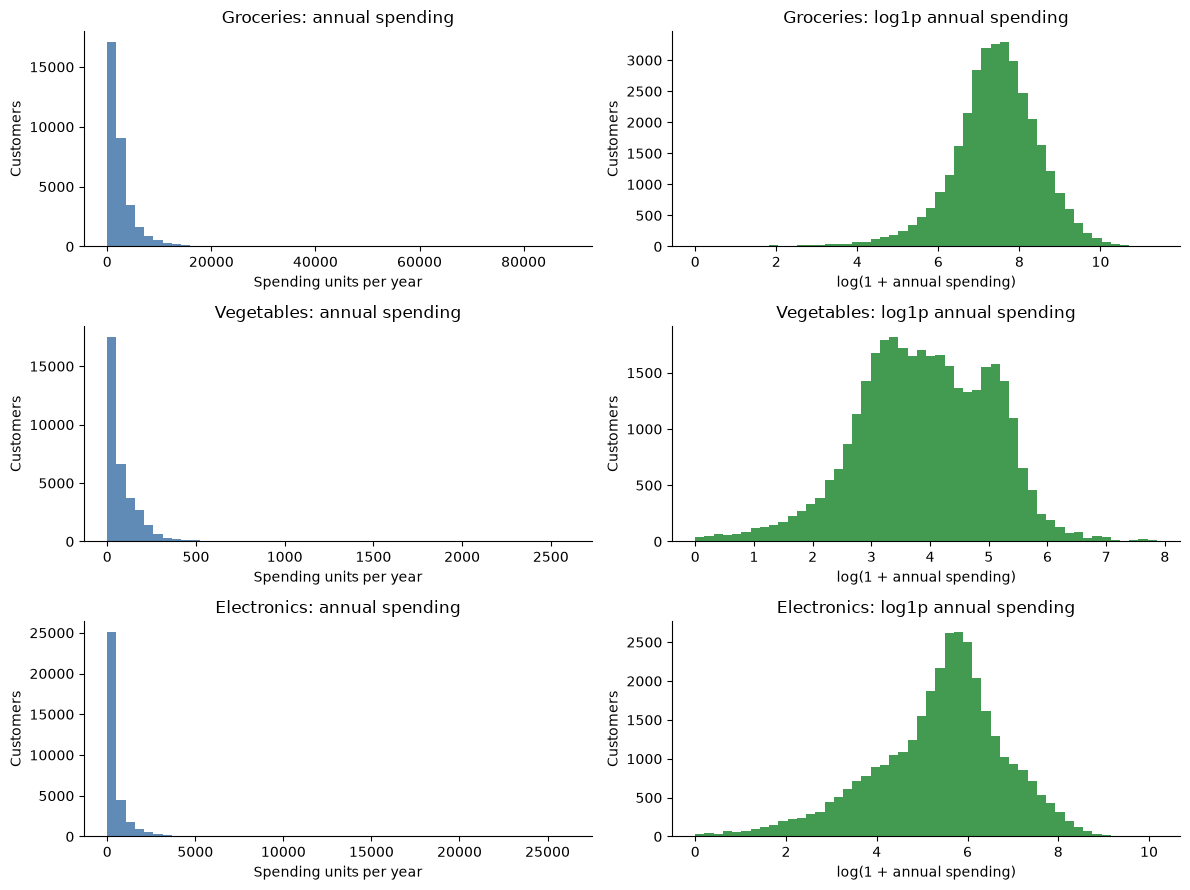

In [4]:
feature_summary = summarize_features(X)
display(feature_summary.round(2))

example_columns = [
    "spend_per_year_groceries",
    "spend_per_year_vegetables",
    "spend_per_year_electronics",
]
fig = plot_spending_transformation(X, example_columns)
fig.savefig(figure_dir / "spending_transformations.png", dpi=160, bbox_inches="tight")
plt.show()

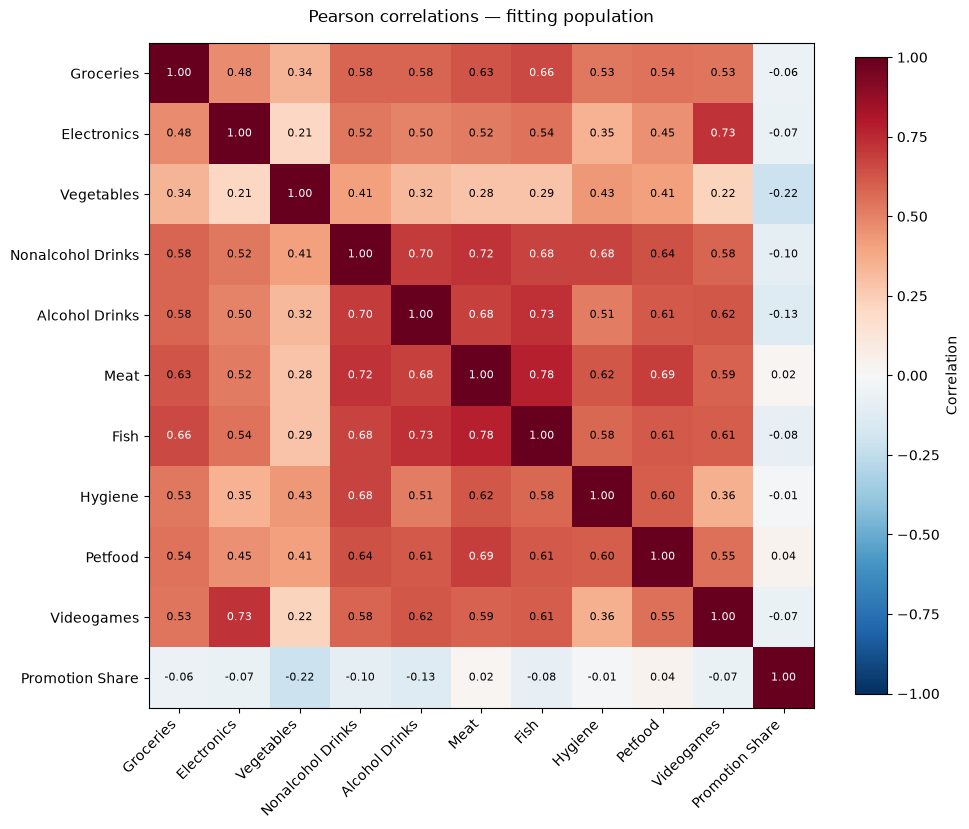

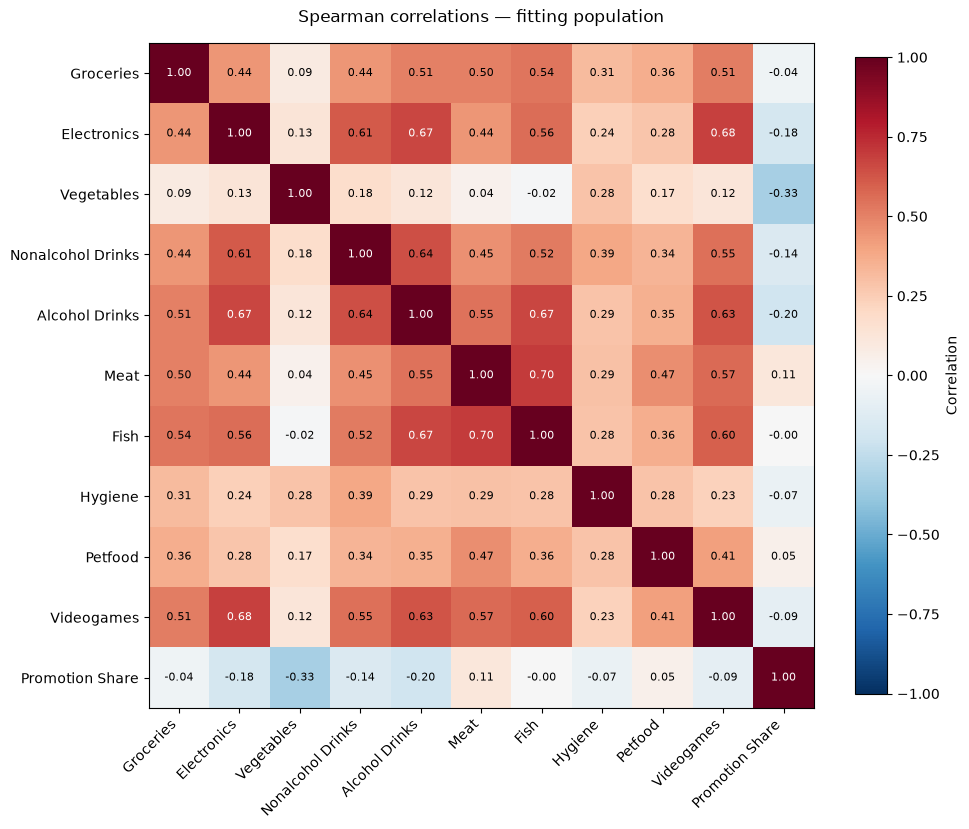

In [5]:
for method in ["pearson", "spearman"]:
    fig = plot_correlations(X, method=method)
    fig.savefig(figure_dir / f"correlations_{method}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 5. Fit three candidate representations

| Candidate | Spending transformation | Scaling | Reduction |
|---|---|---|---|
| A: original_scaled | None | StandardScaler | None |
| B: log_scaled | log1p spending only | StandardScaler | None |
| C: log_pca | Same as B | Same fitted scaler as B | PCA retaining at least 90% variance |

Promotion share is not logged. StandardScaler is used for A and B to isolate the effect of log transformation. It does not remove outliers or guarantee normal distributions. Log transformation compresses large spending differences; it may help reveal preferences but can weaken distinctions among high-value customers.

PCA is fitted without whitening. Its retained scores are not standardized again: doing so would define a different distance weighting.

In [6]:
representations, artifacts = prepare_representations(
    X, spend_columns, variance_threshold=VARIANCE_THRESHOLD,
)
X_original_scaled = representations["original_scaled"]
X_log_scaled = representations["log_scaled"]
X_pca = representations["log_pca"]

X_log = X.copy()
X_log[spend_columns] = np.log1p(X_log[spend_columns])

skew_comparison = pd.DataFrame({
    "original_skewness": X[spend_columns].skew(),
    "log_skewness": X_log[spend_columns].skew(),
})
display(skew_comparison.round(2))
display(X_log_scaled.head())

,original_skewness,log_skewness
spend_per_year_groceries,7.19,-0.72
spend_per_year_electronics,7.10,-0.61
spend_per_year_vegetables,6.97,-0.24
spend_per_year_nonalcohol_drinks,6.34,-0.12
spend_per_year_alcohol_drinks,6.23,-0.17
spend_per_year_meat,5.67,-1.17
spend_per_year_fish,6.07,-0.67
spend_per_year_hygiene,7.39,-0.68
spend_per_year_petfood,5.57,-0.36
spend_per_year_videogames,5.20,0.00


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames,pct_prod_in_promotion
customer_id,,,,,,,,,,,
29930,-0.365209,0.904641,0.655123,1.480420,0.970515,1.015123,1.283547,0.152227,0.911761,0.615597,-0.579638
6813,-0.762965,-2.787204,0.262359,-1.880604,-1.923426,-0.107469,-0.527827,-0.544371,-0.550493,-1.522918,-0.724064
39451,-0.363621,0.237650,0.731506,0.642787,0.712803,0.256359,0.750527,0.158903,-0.932736,-0.271783,-0.809194
21557,-0.623025,1.074850,-2.546180,-1.091982,0.571192,-0.150816,-0.103281,-1.839743,-0.683600,0.290774,-0.173085
16415,0.758823,0.088003,-0.764556,0.363861,-0.428126,0.065483,0.584269,0.365763,-1.185634,-1.236869,0.059430


## 6. PCA diagnostics
Variance retention is not a measure of business usefulness or clustering accuracy. Inspect component coefficients and promotion representation rather than assuming 90% variance preserves every useful distinction. Components and their signs should not be named before reviewing the results.

,component,explained_variance,cumulative_variance
0,1,0.4102,0.4102
1,2,0.1532,0.5634
2,3,0.1028,0.6662
3,4,0.0652,0.7313
4,5,0.0576,0.7890
5,6,0.0530,0.8419
6,7,0.0470,0.8890
7,8,0.0375,0.9265
8,9,0.0302,0.9567
9,10,0.0260,0.9826


Retained components: 8
Retained variance: 92.65%


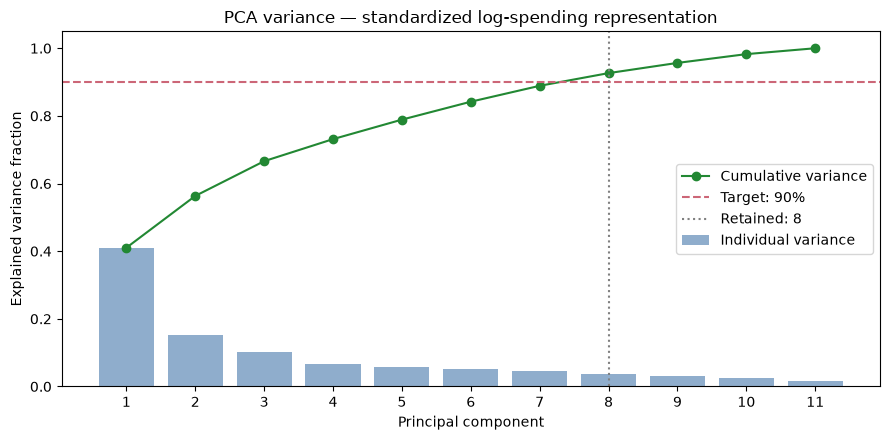

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
spend_per_year_groceries,0.314,-0.088,0.116,-0.063,0.677,0.540,-0.343,0.064
spend_per_year_electronics,0.349,0.151,-0.301,0.105,-0.340,0.243,-0.062,-0.290
spend_per_year_vegetables,0.090,0.545,0.390,0.168,0.180,0.173,0.669,-0.046
spend_per_year_nonalcohol_drinks,0.367,0.186,-0.025,-0.058,-0.284,0.041,-0.063,0.693
spend_per_year_alcohol_drinks,0.394,0.091,-0.186,-0.065,-0.040,-0.070,0.069,0.307
spend_per_year_meat,0.305,-0.470,0.055,-0.132,0.123,-0.221,0.318,-0.090
spend_per_year_fish,0.360,-0.318,-0.071,-0.206,0.121,-0.222,0.354,-0.054
spend_per_year_hygiene,0.216,0.192,0.543,-0.614,-0.261,-0.083,-0.271,-0.298
spend_per_year_petfood,0.261,-0.045,0.444,0.630,0.045,-0.455,-0.315,0.017
spend_per_year_videogames,0.369,0.009,-0.193,0.301,-0.175,0.197,-0.013,-0.459


,variance_fraction_retained
spend_per_year_groceries,0.999
spend_per_year_electronics,0.842
spend_per_year_vegetables,0.999
spend_per_year_nonalcohol_drinks,0.922
spend_per_year_alcohol_drinks,0.803
spend_per_year_meat,0.902
spend_per_year_fish,0.896
spend_per_year_hygiene,0.998
spend_per_year_petfood,0.991
spend_per_year_videogames,0.850


In [7]:
pca = artifacts["pca"]
variance_table, coefficients = pca_diagnostics(X_log_scaled, pca)
display(variance_table.round(4))
print(f"Retained components: {pca.n_components_}")
print(f"Retained variance: {pca.explained_variance_ratio_.sum():.2%}")
fig = plot_pca_variance(variance_table, pca.n_components_, VARIANCE_THRESHOLD)
fig.savefig(figure_dir / "pca_variance.png", dpi=160, bbox_inches="tight")
plt.show()
display(coefficients.round(3))

# Retained variance fraction for each standardized input feature.
feature_retention = pd.Series(
    (pca.components_ ** 2 * pca.explained_variance_[:, None]).sum(axis=0)
    / X_log_scaled.var(ddof=1).to_numpy(),
    index=X.columns, name="variance_fraction_retained",
)
display(feature_retention.to_frame().round(3))

### Component associations
These associations help interpretation, not feature selection by an automatic threshold. In particular, inspect associations with tenure and total spending. Total spending below is for diagnosis only and is not added to any model matrix.

In [8]:
diagnostics = fit_customers[["customer_lifetime", "age", "pct_prod_in_promotion"]].copy()
diagnostics["total_annual_spending"] = fit_customers[spend_columns].sum(axis=1)
combined = X_pca.join(diagnostics)
component_associations = combined.corr(method="spearman").loc[
    X_pca.columns, diagnostics.columns
]
display(component_associations.round(3))

,customer_lifetime,age,pct_prod_in_promotion,total_annual_spending
PC1,-0.504,-0.119,-0.120,0.848
PC2,0.002,0.038,-0.744,0.047
PC3,-0.334,-0.118,0.366,0.018
PC4,-0.282,-0.045,0.097,-0.025
PC5,0.036,0.004,-0.369,0.279
PC6,-0.038,0.018,0.341,0.263
PC7,-0.016,0.025,0.097,-0.126
PC8,-0.012,-0.102,0.137,-0.018


## 7. Validation and candidate summary
All candidates must contain the same customers in the same order. Inverse-scaling checks confirm that spending units have not accidentally been overwritten. Transforming the fitting population with saved artifacts must reproduce the prepared matrices.

In [9]:
for name, matrix in representations.items():
    assert matrix.index.equals(X.index)
    assert np.isfinite(matrix.to_numpy()).all()

np.testing.assert_allclose(
    artifacts["original_scaler"].inverse_transform(X_original_scaled),
    X.to_numpy(), atol=1e-8,
)
np.testing.assert_allclose(
    artifacts["log_scaler"].inverse_transform(X_log_scaled),
    X_log.to_numpy(), atol=1e-8,
)
replayed = transform_customers(X, artifacts)
for name in representations:
    np.testing.assert_allclose(replayed[name], representations[name], atol=1e-8)

representation_summary = pd.DataFrame([
    {"representation": name, "customers": len(matrix), "features": matrix.shape[1],
     "finite_values": bool(np.isfinite(matrix.to_numpy()).all())}
    for name, matrix in representations.items()
])
display(representation_summary)
print("Alignment, finite-value, inverse-scaling, and replay checks passed.")

,representation,customers,features,finite_values
0,original_scaled,33715,11,True
1,log_scaled,33715,11,True
2,log_pca,33715,8,True


Alignment, finite-value, inverse-scaling, and replay checks passed.


## 8. Export
CSV files include customer_id as an identifier, not a feature. Notebook 5 must load them with `index_col="customer_id"`. Fitted objects are saved with joblib; only load trusted artifact files and retain the recorded library versions.

Original-unit profiles and all deferred customers are preserved separately. No cluster labels are created here.

In [10]:
for name, matrix in representations.items():
    matrix.to_csv(feature_dir / f"{name}.csv", index_label="customer_id")

X.to_csv(feature_dir / "fitting_features_original_units.csv", index_label="customer_id")
population.to_csv(feature_dir / "customer_population.csv", index=False)
customer_info.to_csv(feature_dir / "customer_profiles.csv", index=False)
customer_info.loc[~customer_info["customer_id"].isin(fit_ids)].to_csv(
    feature_dir / "deferred_or_excluded_customers.csv", index=False,
)
joblib.dump(artifacts, artifact_dir / "feature_transformations.joblib")

feature_summary.to_csv(table_dir / "feature_summary.csv")
skew_comparison.to_csv(table_dir / "feature_skew_comparison.csv")
variance_table.to_csv(table_dir / "pca_variance.csv", index=False)
coefficients.to_csv(table_dir / "pca_coefficients.csv", index_label="feature")
feature_retention.to_csv(table_dir / "pca_feature_retention.csv", index_label="feature")
component_associations.to_csv(table_dir / "pca_diagnostic_associations.csv")
representation_summary.to_csv(table_dir / "representation_summary.csv", index=False)

settings = {
    "source_data": "data/preprocessed/customer_info_clean.csv",
    "source_flags": "data/preprocessed/customer_outlier_flags.csv",
    "fitting_policy": "Positive tenure; reviewed exclusions respected; detector flags alone do not exclude",
    "zero_tenure_policy": "Deferred pending annual-spending review; no automatic assignment",
    "features": feature_columns,
    "logged_features": spend_columns,
    "scaler": "StandardScaler for both baseline representations",
    "pca_variance_target": VARIANCE_THRESHOLD,
    "pca_components_retained": int(pca.n_components_),
    "pca_retained_variance": float(pca.explained_variance_ratio_.sum()),
    "pca_whiten": False,
    "population_counts": population["status"].value_counts().to_dict(),
    "python_version": platform.python_version(),
    "package_versions": {
        package: importlib.metadata.version(package)
        for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "joblib"]
    },
}
(artifact_dir / "feature_settings.json").write_text(json.dumps(settings, indent=2))
print("Feature matrices, population status, diagnostics, and fitted transformations exported.")

Feature matrices, population status, diagnostics, and fitted transformations exported.


## 9. Interpretation and handoff

### Interpretation
- **Population:** 33,715 of 34,060 customers (98.99%) were fitted. The 345 zero-tenure customers (1.01%) were deferred; no customers were explicitly excluded. The three exported representations contain the same 33,715 customers and have finite values.
- **Log transformation:** `log1p` reduced the strong positive skew in all ten annual-spending features. The largest reductions were for hygiene (skew 7.39 to -0.68), groceries (7.19 to -0.72), and electronics (7.10 to -0.61). Meat is now moderately negatively skewed (-1.17), so the transformation compresses the high-spending tail rather than making every feature perfectly symmetric.
- **PCA:** The 90% variance target is met with 8 of 11 components, retaining 92.65% cumulative variance. The 8-component representation is therefore a lower-dimensional candidate, not an automatic winner.
- **Promotion share:** The retained components preserve 98.94% of the promotion-share feature's variance. This is its PCA reconstruction fraction, distinct from the overall 92.65% cumulative variance.
- **Component associations:** PC1 is strongly associated with total annual spending (Spearman ρ = 0.848) and moderately associated with tenure (ρ = -0.504). PC2 is strongly associated with promotion share (ρ = -0.744). PCA component signs are arbitrary, and these diagnostic associations are not causal; tenure and total spending were not clustering features.

### Handoff to Notebook 5
Compare clustering on the same 33,715 fitted customers using the original-scaled, log-scaled, and 8-component log-PCA representations. Assess cluster sizes, stability, internal diagnostics, and profiles in original spending units; treat metrics from different feature spaces as supporting evidence rather than directly comparable proof of business quality. Preserve `customer_id` as an identifier, not a feature, and use the saved transformations consistently when preparing new customers.

The 345 zero-tenure customers remain unassigned until their annual-spending inputs and handling policy are reviewed. Before deployment, define and validate how every deferred customer will be processed and assigned; do not infer a final assignment policy from this notebook.